# Ingredient-name merge audit

We assess whether cosine similarity, word-token Jaccard, and character-trigram Jaccard can identify equivalent ingredient names.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

candidates = (Path.cwd() / "results", Path.cwd().parent / "results")
results = next(
    (path for path in candidates if (path / "ingredient_merge_eval.csv").is_file()),
    None,
)
if results is None:
    raise FileNotFoundError(
        "Expected results/ingredient_merge_eval.csv near the notebook or repository root."
    )

In [ ]:
audit = pd.read_csv(results / "ingredient_merge_eval.csv")
errors = pd.read_csv(results / "ingredient_merge_errors.csv")

columns = [
    "validation_source_rows",
    "validation_blank_rows",
    "validation_duplicate_rows",
    "test_source_rows",
    "test_blank_rows",
    "test_duplicate_rows",
    "original_shared_pairs",
    "original_shared_ingredients",
    "dev_holdout_shared_ingredients",
]
display(audit.loc[0, columns].rename("count").to_frame())
display(
    audit[["split", "n_pairs", "positive_pairs"]].drop_duplicates(ignore_index=True)
)

,count
validation_source_rows,200
validation_blank_rows,0
validation_duplicate_rows,0
test_source_rows,400
test_blank_rows,4
test_duplicate_rows,0
original_shared_pairs,4
original_shared_ingredients,61
dev_holdout_shared_ingredients,0


,split,n_pairs,positive_pairs
0,development,152,84
1,grouped_holdout,48,24
2,original_test_exploratory,392,120


Both labelled sets define the connected components of ingredient names. We split the validation pairs by component and fit the cutoffs and logistic model on development pairs. The original test split is exploratory. Exact repeated pairs are retained in validation.


,method,accepted_count,false_merges,precision,recall,f1,selected_by_development
6,cosine_cutoff,38,18,0.526,0.833,0.645,False
7,token_cutoff,46,22,0.522,1.000,0.686,False
8,trigram_cutoff,42,21,0.500,0.875,0.636,False
9,all_three,38,18,0.526,0.833,0.645,True
10,cosine_and_either,38,18,0.526,0.833,0.645,False
11,logistic_l2,29,10,0.655,0.792,0.717,False


,method,accepted_count,false_merges,precision,recall,f1,selected_by_development
12,cosine_cutoff,187,107,0.428,0.667,0.521,False
13,token_cutoff,368,254,0.310,0.950,0.467,False
14,trigram_cutoff,290,193,0.334,0.808,0.473,False
15,all_three,159,91,0.428,0.567,0.487,True
16,cosine_and_either,163,93,0.429,0.583,0.495,False
17,logistic_l2,77,34,0.558,0.358,0.437,False


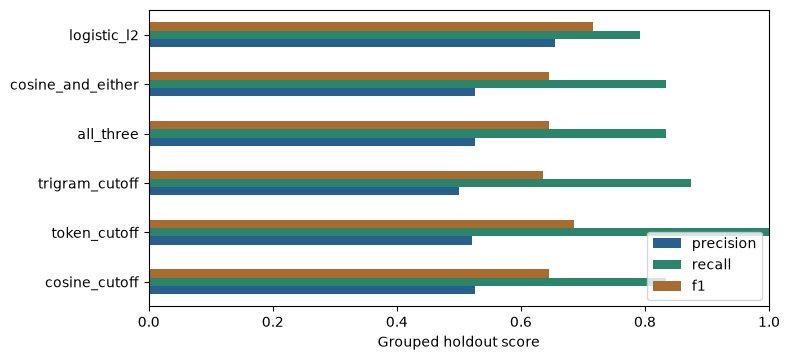

In [ ]:
measures = [
    "method",
    "accepted_count",
    "false_merges",
    "precision",
    "recall",
    "f1",
    "selected_by_development",
]
holdout = audit.loc[audit["split"] == "grouped_holdout", measures]
exploratory = audit.loc[audit["split"] == "original_test_exploratory", measures]
display(holdout.round(3))
display(exploratory.round(3))

ax = holdout.set_index("method")[["precision", "recall", "f1"]].plot.barh(
    figsize=(8, 3.7),
    color=["#285f8f", "#2a856b", "#a86c31"],
)
ax.set(xlim=(0, 1), xlabel="Grouped holdout score", ylabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [4]:
selected = audit.loc[audit["selected_by_development"], "method"].iloc[0]
examples = errors.loc[errors["method"] == selected]
display(examples.groupby("split", sort=False).head(5).round(3))

,split,method,ingredient_1,ingredient_2,similarity,token_jaccard,char_trigram,merge_label
0,grouped_holdout,all_three,cherry in syrup,cherry syrup,0.965,0.667,0.643,0
1,grouped_holdout,all_three,cooked short-grain white rice,short-grain white rice,0.928,0.750,0.741,0
2,grouped_holdout,all_three,pineapple juice concentrate,pineapple-orange juice concentrate,0.923,0.500,0.727,0
3,grouped_holdout,all_three,frozen pea,frozen snow pea,0.916,0.667,0.500,0
4,grouped_holdout,all_three,bailey caramel irish cream,bailey original irish cream,0.897,0.600,0.485,0
107,original_test_exploratory,all_three,whole grain oat,whole grain oatmeal,0.966,0.500,0.765,0
108,original_test_exploratory,all_three,chocolate mousse mix,chocolate raspberry mousse mix,0.949,0.750,0.607,0
109,original_test_exploratory,all_three,low-fat vanilla yogurt,plain low-fat yogurt,0.938,0.500,0.407,0
110,original_test_exploratory,all_three,beef sausage,sausage meat,0.928,0.333,0.333,0
111,original_test_exploratory,all_three,foie gra,foie gra pate,0.926,0.667,0.545,0


The holdout measures performance on unseen ingredient components within the labelled candidate pool. Candidate generation and earlier threshold exploration limit conclusions about the full vocabulary.
